# I giocatori che ho visto a San Siro
Statistiche sulle formazioni delle partite viste dal vivo (Inter e avversari).

Serve `formazioni_complete.csv` (ESPN + Supercoppe da Wikipedia, vedi sotto) nella stessa cartella del notebook.
Se hai ancora i due file separati, la prima cella li unisce da sola.

**Nota sui minuti**: ESPN indica solo *se* un giocatore è entrato o uscito, non il minuto, quindi qui si contano
partite, titolarità e subentri, non i minuti giocati.

In [46]:
import os
import re
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

CSV_FORMAZIONI = "formazioni_complete.csv"
CSV_ESPN = "formazioni.csv"
CSV_SUPERCOPPA = "formazioni_supercoppa_wikipedia.csv"
CSV_PRESENZE = "presenze_stadio.csv"
TOP = 20   # quanti giocatori mostrare nelle classifiche

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 200)
plt.rcParams["figure.figsize"] = (9, 5)

## 1. Caricamento

In [47]:
if os.path.exists(CSV_FORMAZIONI):
    f = pd.read_csv(CSV_FORMAZIONI, dtype={"athlete_id": "string", "numero": "string"})
else:
    pezzi = [pd.read_csv(p, dtype={"athlete_id": "string", "numero": "string"})
             for p in (CSV_ESPN, CSV_SUPERCOPPA) if os.path.exists(p)]
    f = pd.concat(pezzi, ignore_index=True)
f["data"] = pd.to_datetime(f["data"])


def vero(x):
    return str(x).strip().lower() not in ("", "nan", "false", "none", "0", "<na>")


f["titolare"] = f["titolare"].map(vero)
f["sub_in"] = f["sub_in_raw"].map(vero)      # ESPN: True/vuoto; Wikipedia: minuto o vuoto
f["sub_out"] = f["sub_out_raw"].map(vero)
f["ha_giocato"] = f["titolare"] | f["sub_in"]
f["stagione"] = f["data"].map(lambda d: f"{d.year}-{d.year + 1}" if d.month >= 7 else f"{d.year - 1}-{d.year}")

print(f"{len(f)} righe, {f['data'].nunique()} partite, dal {f['data'].min():%d/%m/%Y} al {f['data'].max():%d/%m/%Y}")
f.head()

3431 righe, 76 partite, dal 19/08/2007 al 25/10/2026


,data,competizione,avversario,event_id,squadra,nome_squadra,lato,modulo,giocatore,athlete_id,numero,ruolo,titolare,sub_in_raw,sub_out_raw,ammonito,ammonito_min,espulso,espulso_min,sub_in,sub_out,ha_giocato,stagione
0,2010-04-24,Serie A,Atalanta,278519,Inter,Internazionale,home,4-1-2-1-2,Julio César De León,39748,12,G,True,NaN,NaN,NaN,NaN,NaN,NaN,False,False,True,2009-2010
1,2010-04-24,Serie A,Atalanta,278519,Inter,Internazionale,home,4-1-2-1-2,Marco Materazzi,10027,23,CD-L,True,NaN,NaN,NaN,NaN,NaN,NaN,False,False,True,2009-2010
2,2010-04-24,Serie A,Atalanta,278519,Inter,Internazionale,home,4-1-2-1-2,Iván Córdoba,11922,2,CD-R,True,NaN,NaN,NaN,NaN,NaN,NaN,False,False,True,2009-2010
3,2010-04-24,Serie A,Atalanta,278519,Inter,Internazionale,home,4-1-2-1-2,McDonald Mariga,108471,17,DM,True,NaN,NaN,NaN,NaN,NaN,NaN,False,False,True,2009-2010
4,2010-04-24,Serie A,Atalanta,278519,Inter,Internazionale,home,4-1-2-1-2,Cristian Chivu,10996,26,LB,True,NaN,NaN,NaN,NaN,NaN,NaN,False,False,True,2009-2010


### Controlli: partite mancanti e formazioni strane

In [48]:
pres = pd.read_csv(CSV_PRESENZE, parse_dates=["data"])
senza = pres[~pres["data"].isin(f["data"].unique())]
print(f"Partite in {CSV_PRESENZE}: {len(pres)} | con formazione: {f['data'].nunique()} | senza: {len(senza)}")
if len(senza):
    display(senza[["data", "competizione", "avversario"]])

tit = f[f["titolare"]].groupby(["data", "squadra"]).size().unstack(fill_value=0)
strane = tit[(tit.get("Inter", 0) != 11) | (tit.get("Avversario", 0) != 11)]
print(f"Partite in cui una squadra non ha 11 titolari: {len(strane)}")
strane

Partite in presenze_stadio.csv: 76 | con formazione: 76 | senza: 0
Partite in cui una squadra non ha 11 titolari: 0


squadra,Avversario,Inter
data,,


### Identità dei giocatori
ESPN dà un id per giocatore. Le righe da Wikipedia (le due Supercoppe) non ce l'hanno: provo ad abbinarle a un giocatore
ESPN della stessa squadra confrontando le parole del nome ("Júlio César" ⊂ "Julio César De León").
Se l'abbinamento è ambiguo o non c'è, il giocatore resta identificato dal solo nome.

In [49]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z ]", " ", s).split()


espn = f[f["athlete_id"].notna()]
token = {}
for (sq, aid), g in espn.groupby(["squadra", "athlete_id"]):
    token[(sq, aid)] = [set(norm(n)) for n in g["giocatore"].unique()]


def trova_id(nome, squadra):
    t = set(norm(nome))
    if not t:
        return None
    cand = {aid for (sq, aid), liste in token.items() if sq == squadra and any(t <= x for x in liste)}
    return next(iter(cand)) if len(cand) == 1 else None


f["chiave"] = f["athlete_id"].astype(object)
senza_id = f[f["athlete_id"].isna()].index
non_abbinati = []
for i in senza_id:
    aid = trova_id(f.at[i, "giocatore"], f.at[i, "squadra"])
    if aid is not None:
        f.at[i, "chiave"] = aid
    else:
        f.at[i, "chiave"] = "wiki:" + " ".join(norm(f.at[i, "giocatore"]))
        non_abbinati.append({"data": f.at[i, "data"].date(), "squadra": f.at[i, "squadra"],
                             "giocatore": f.at[i, "giocatore"]})

nome_per_chiave = f.groupby("chiave")["giocatore"].agg(lambda s: s.value_counts().index[0])
f["nome"] = f["chiave"].map(nome_per_chiave)

print(f"Righe da Wikipedia: {len(senza_id)} | abbinate a un id ESPN: {len(senza_id) - len(non_abbinati)} | non abbinate: {len(non_abbinati)}")
pd.DataFrame(non_abbinati)

Righe da Wikipedia: 72 | abbinate a un id ESPN: 29 | non abbinate: 43


,data,squadra,giocatore
0,2007-08-19,Inter,Nicolás Burdisso
1,2007-08-19,Inter,Patrick Vieira
2,2007-08-19,Inter,Olivier Dacourt
3,2007-08-19,Inter,David Suazo
4,2007-08-19,Inter,Zlatan Ibrahimović
5,2007-08-19,Inter,Francesco Toldo
6,2007-08-19,Inter,Maxwell
7,2007-08-19,Inter,Luís Figo
8,2007-08-19,Inter,Julio Cruz
9,2007-08-19,Inter,Hernán Crespo


## 2. Giocatori dell'Inter che hai visto

Giocatori dell'Inter visti giocare: 127 (in 76 partite)


,giocatore,partite_viste,da_titolare,subentrato,in_panchina_senza_entrare,stagioni,prima,ultima
chiave,,,,,,,,
204441,Nicolò Barella,57,54,3,5,7,2020-01-29,2026-10-25
194748,Federico Dimarco,56,43,13,7,7,2020-01-29,2026-10-25
219713,Lautaro Martínez,54,41,13,1,7,2020-01-29,2026-10-13
170785,Hakan Çalhanoglu,52,42,10,4,6,2021-08-21,2026-10-25
249280,Alessandro Bastoni,51,46,5,7,7,2020-01-29,2026-10-25
213248,Denzel Dumfries,44,36,8,7,5,2021-08-21,2026-05-17
147625,Henrikh Mkhitaryan,37,27,10,6,5,2022-08-30,2026-10-25
141443,Stefan de Vrij,32,28,4,19,5,2021-08-21,2026-05-17
102337,Edin Dzeko,32,23,9,3,2,2021-08-21,2023-05-27


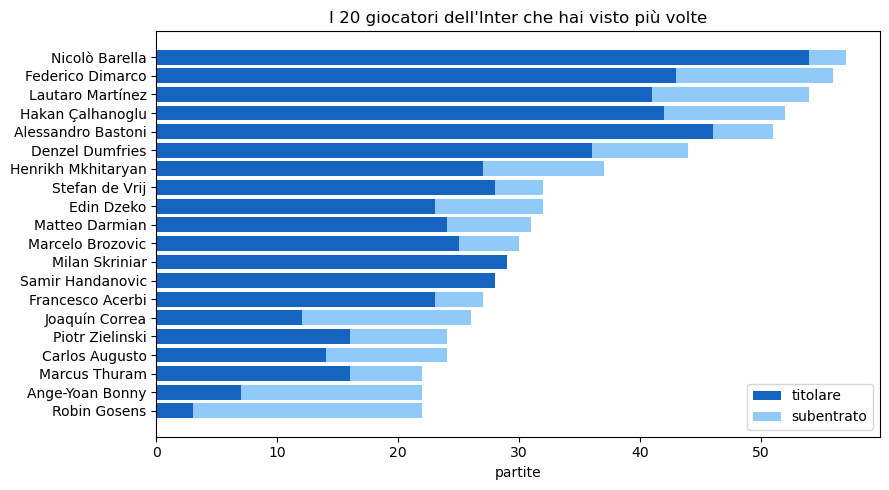

In [50]:
def tabella_giocatori(df):
    g = df.groupby("chiave")
    t = pd.DataFrame({
        "giocatore": g["nome"].first(),
        "partite_viste": g["ha_giocato"].sum(),
        "da_titolare": g["titolare"].sum(),
        "subentrato": (df["sub_in"] & ~df["titolare"]).groupby(df["chiave"]).sum(),
        "in_panchina_senza_entrare": (~df["ha_giocato"]).groupby(df["chiave"]).sum(),
        "stagioni": g["stagione"].nunique(),
        "prima": g["data"].min().dt.date,
        "ultima": g["data"].max().dt.date,
    })
    return t.sort_values(["partite_viste", "da_titolare"], ascending=False)


inter = f[f["squadra"] == "Inter"]
ti = tabella_giocatori(inter)
visti = ti[ti["partite_viste"] > 0]
print(f"Giocatori dell'Inter visti giocare: {len(visti)} (in {inter['data'].nunique()} partite)")
display(visti.head(TOP))

top = visti.head(TOP).iloc[::-1]
plt.barh(top["giocatore"], top["da_titolare"], label="titolare", color="#1565c0")
plt.barh(top["giocatore"], top["subentrato"], left=top["da_titolare"], label="subentrato", color="#90caf9")
plt.title(f"I {TOP} giocatori dell'Inter che hai visto più volte")
plt.xlabel("partite")
plt.legend()
plt.tight_layout()
plt.show()

### Quante volte hai visto ogni giocatore

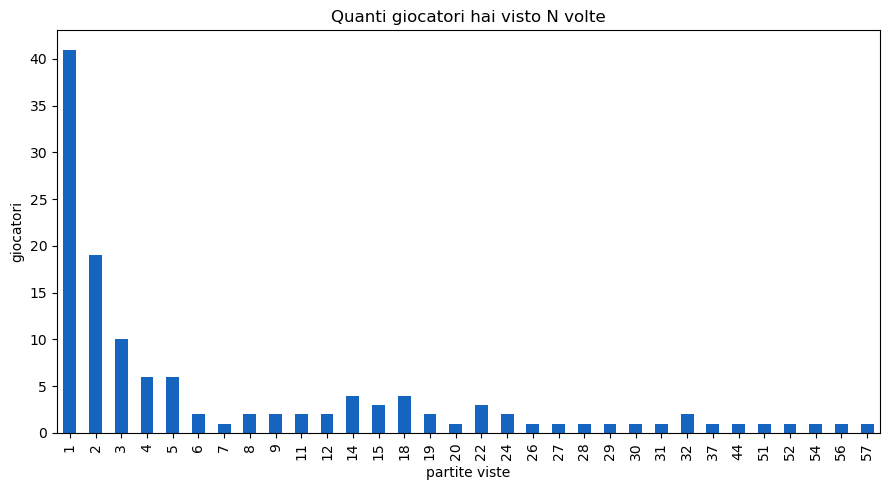

Visti una volta sola: 41 giocatori su 127


,giocatore,prima,da_titolare,subentrato
chiave,,,,
wiki:luis figo,Luís Figo,2007-08-19,0,1
wiki:zlatan ibrahimovic,Zlatan Ibrahimović,2007-08-19,1,0
wiki:patrick vieira,Patrick Vieira,2007-08-19,1,0
wiki:olivier dacourt,Olivier Dacourt,2007-08-19,1,0
wiki:nicolas burdisso,Nicolás Burdisso,2007-08-19,1,0
wiki:david suazo,David Suazo,2007-08-19,1,0
wiki:julio cruz,Julio Cruz,2007-08-19,0,1
24977,Sulley Muntari,2010-04-24,1,0
13849,Thiago Motta,2010-04-24,0,1


In [51]:
distribuzione = visti["partite_viste"].value_counts().sort_index()
distribuzione.plot(kind="bar", color="#1565c0")
plt.title("Quanti giocatori hai visto N volte")
plt.xlabel("partite viste")
plt.ylabel("giocatori")
plt.tight_layout()
plt.show()

una = visti[visti["partite_viste"] == 1]
print(f"Visti una volta sola: {len(una)} giocatori su {len(visti)}")
una.sort_values("prima")[["giocatore", "prima", "da_titolare", "subentrato"]]

In [52]:
# Il tuo "undici più visto" (i più titolari; l'ordine del ruolo non è considerato)
ti.sort_values(["da_titolare", "partite_viste"], ascending=False).head(11)[["giocatore", "da_titolare", "partite_viste"]]

,giocatore,da_titolare,partite_viste
chiave,,,
204441,Nicolò Barella,54,57
249280,Alessandro Bastoni,46,51
194748,Federico Dimarco,43,56
170785,Hakan Çalhanoglu,42,52
219713,Lautaro Martínez,41,54
213248,Denzel Dumfries,36,44
175195,Milan Skriniar,29,29
141443,Stefan de Vrij,28,32
44323,Samir Handanovic,28,28


In [53]:
# Giocatori che hai visto solo in panchina (convocati ma mai entrati)
ti[ti["partite_viste"] == 0][["giocatore", "in_panchina_senza_entrare", "prima", "ultima"]]

,giocatore,in_panchina_senza_entrare,prima,ultima
chiave,,,,
119612,Stevan Jovetic,1,2017-08-20,2017-08-20
11978,Paolo Orlandoni,2,2010-04-24,2011-12-07
121811,Davide Santon,2,2018-04-17,2018-05-12
143696,Lorenzo Crisetig,1,2011-12-07,2011-12-07
144720,Andrei Radu,14,2021-08-21,2022-05-06
152044,Cristiano Biraghi,1,2020-01-29,2020-01-29
163990,Matteo Bianchetti,1,2012-09-30,2012-09-30
165580,Marko Livaja,3,2012-08-09,2012-09-30
173282,Alfred Duncan,1,2012-09-30,2012-09-30


## 3. Per stagione

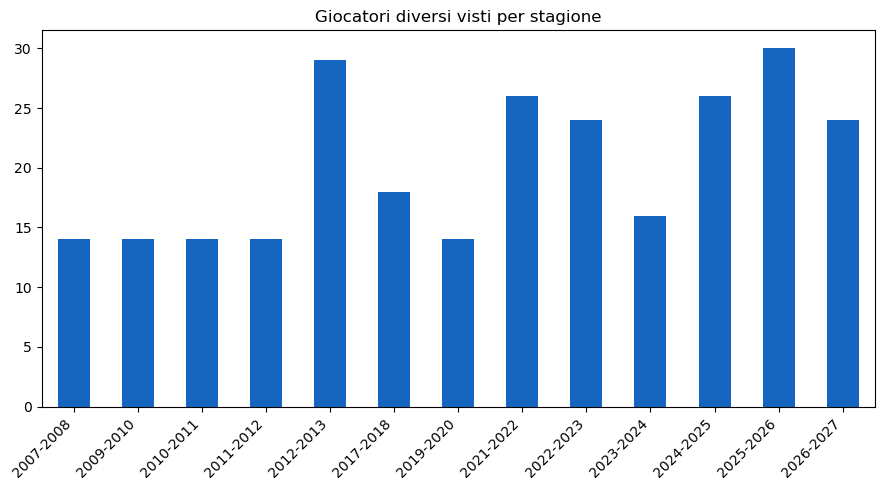

,giocatori diversi visti,partite viste
stagione,,
2007-2008,14,1
2009-2010,14,1
2010-2011,14,1
2011-2012,14,1
2012-2013,29,5
2017-2018,18,3
2019-2020,14,1
2021-2022,26,14
2022-2023,24,21


In [54]:
per_stagione = (inter[inter["ha_giocato"]].groupby("stagione")["chiave"].nunique()
                .rename("giocatori diversi visti").to_frame())
per_stagione["partite viste"] = inter.groupby("stagione")["data"].nunique()
per_stagione.plot(kind="bar", y="giocatori diversi visti", legend=False, color="#1565c0")
plt.title("Giocatori diversi visti per stagione")
plt.xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
per_stagione

In [55]:
# Chi hai visto di più in ogni stagione
righe = []
for stagione, g in inter[inter["ha_giocato"]].groupby("stagione"):
    r = g.groupby("chiave").agg(giocatore=("nome", "first"), partite=("data", "nunique")).sort_values("partite", ascending=False).head(3)
    righe.append({"stagione": stagione, "più visti": "; ".join(f"{x.giocatore} ({x.partite})" for x in r.itertuples())})
pd.DataFrame(righe)

,stagione,più visti
0,2007-2008,Marco Materazzi (1); Cristian Chivu (1); Dejan...
1,2009-2010,Marco Materazzi (1); McDonald Mariga (1); Cris...
2,2010-2011,Marco Materazzi (1); McDonald Mariga (1); Cris...
3,2011-2012,Luca Castellazzi (1); Cristian Chivu (1); Davi...
4,2012-2013,Andrea Ranocchia (5); Fredy Guarín (5); Javier...
5,2017-2018,Ivan Perisic (3); Milan Skriniar (3); Borja Va...
6,2019-2020,Antonio Candreva (1); Diego Godín (1); Victor ...
7,2021-2022,Samir Handanovic (14); Milan Skriniar (14); Ma...
8,2022-2023,Lautaro Martínez (21); Nicolò Barella (20); Ha...
9,2023-2024,Juan Cuadrado (1); Stefan de Vrij (1); Henrikh...


## 4. Gli avversari

In [56]:
avv = f[f["squadra"] == "Avversario"]
ta = tabella_giocatori(avv)
ta["squadra_più_frequente"] = avv.groupby("chiave")["nome_squadra"].agg(lambda s: s.value_counts().index[0])
vis_a = ta[ta["partite_viste"] > 0]
print(f"Avversari diversi visti giocare: {len(vis_a)}")
vis_a.head(TOP)[["giocatore", "squadra_più_frequente", "partite_viste", "da_titolare", "subentrato", "prima", "ultima"]]

Avversari diversi visti giocare: 884


,giocatore,squadra_più_frequente,partite_viste,da_titolare,subentrato,prima,ultima
chiave,,,,,,,
261054,Junior Messias,AC Milan,5,3,2,2022-09-03,2026-02-28
184737,Lorenzo Montipò,Hellas Verona,4,4,0,2022-04-09,2026-05-17
188306,Matteo Politano,Napoli,4,4,0,2018-05-12,2026-09-05
272892,Andrea Colpani,Monza,4,4,0,2023-04-15,2026-08-22
156792,Gianluca Caprari,Monza,4,3,1,2022-04-09,2025-08-12
189974,Giovanni Simeone,Fiorentina,4,3,1,2017-08-20,2025-08-25
223947,Lassana Coulibaly,Salernitana,4,3,1,2022-03-04,2026-01-14
290129,Pierre Kalulu,AC Milan,4,3,1,2022-09-03,2026-02-14
309273,Rasmus Højlund,Atalanta,4,3,1,2023-01-31,2026-09-05


In [57]:
# Giocatori visti sia con l'Inter sia contro l'Inter
conteggi = (f[f["ha_giocato"]].pivot_table(index="chiave", columns="squadra", values="data", aggfunc="nunique", fill_value=0))
entrambi = conteggi[(conteggi.get("Inter", 0) > 0) & (conteggi.get("Avversario", 0) > 0)].copy()
entrambi.insert(0, "giocatore", entrambi.index.map(nome_per_chiave))
entrambi.rename(columns={"Inter": "con l'Inter", "Avversario": "contro l'Inter"}).sort_values("con l'Inter", ascending=False)

squadra,giocatore,contro l'Inter,con l'Inter
chiave,,,
147625,Henrikh Mkhitaryan,1,37
102337,Edin Dzeko,1,32
148842,Francesco Acerbi,1,27
271769,Carlos Augusto,1,24
177782,Piotr Zielinski,1,24
198087,Robin Gosens,1,22
193977,Roberto Gagliardini,2,19
91776,Danilo D'Ambrosio,1,18
308881,Kristjan Asllani,1,18


## 5. Moduli

In [58]:
mod = f[f["modulo"].notna()].drop_duplicates(["data", "squadra"])
print("Moduli dell'Inter nelle partite viste:")
display(mod[mod["squadra"] == "Inter"]["modulo"].value_counts().to_frame("partite"))
print("Moduli degli avversari:")
mod[mod["squadra"] == "Avversario"]["modulo"].value_counts().head(8).to_frame("partite")

Moduli dell'Inter nelle partite viste:


,partite
modulo,
3-5-2,62
4-2-3-1,4
4-1-2-1-2,1
4-4-1-1,1
3-4-1-2,1
3-5-1-1,1


Moduli degli avversari:


,partite
modulo,
3-4-2-1,17
4-2-3-1,12
4-3-3,12
3-5-2,11
4-4-2,3
3-4-1-2,3
5-3-2,3
3-5-1-1,3


## 6. Esporta

In [59]:
visti.reset_index().to_csv("giocatori_inter_visti.csv", index=False, encoding="utf-8-sig")
vis_a.reset_index().to_csv("giocatori_avversari_visti.csv", index=False, encoding="utf-8-sig")
print("Salvati giocatori_inter_visti.csv e giocatori_avversari_visti.csv")

Salvati giocatori_inter_visti.csv e giocatori_avversari_visti.csv
